# Predicción de horas hombre — Entradas a almacén (handhelds)

**Objetivo de negocio:** estimar las **horas hombre** de trabajo de almacén que se necesitarán, a
partir del histórico de entradas (API SGA), para planear personal y turnos.

Este notebook **reutiliza** la carga de datos de `fuente_unica_entradas.ipynb` (§6, API SGA con hora
real) y **replica la estructura y las gráficas** de `Timeseries.ipynb` (SARIMA + Prophet, en *dark
mode*), adaptadas de una serie **mensual** a una serie **horaria**.

> **Variable objetivo — "horas hombre de presencia":** número de usuarios distintos activos en cada
> hora reloj. Una persona presente y trabajando en una hora ⇒ 1 hora-hombre. Es un **proxy de
> presencia** (no horas de nómina), pero es exactamente lo que se programa contra turnos.

# Bibliotecas y funciones

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")  # evita sobre-suscripción de BLAS en la rejilla SARIMAX
import itertools

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

from sklearn.metrics import mean_squared_error, mean_absolute_error
from joblib import Parallel, delayed

from lisa_client import LisaClient, LisaAPIError

Importing plotly failed. Interactive plots will not work.


In [2]:
#@title Dark Mode
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": "#111111", "axes.facecolor": "#111111", "savefig.facecolor": "#111111",
    "axes.edgecolor": "white", "axes.labelcolor": "white", "text.color": "white",
    "xtick.color": "white", "ytick.color": "white",
    "grid.color": "lightgray", "grid.linestyle": "--", "grid.linewidth": 0.5,
    "lines.linewidth": 1.5, "lines.markersize": 5, "font.size": 10,
    "figure.figsize": (8, 6), "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.edgecolor": "white", "legend.frameon": True, "legend.fancybox": False,
})
sns.set_style("darkgrid", {
    "axes.facecolor": "#111111", "figure.facecolor": "#111111", "grid.color": "#333333",
    "text.color": "white", "axes.labelcolor": "white", "xtick.color": "white", "ytick.color": "white",
})

In [3]:
def _oscurecer(fig):
    """Fuerza modo oscuro en figuras que crean su propia Figure (seasonal_decompose,
    plot_diagnostics, Prophet.plot / plot_components), que no heredan bien los rcParams."""
    fig.patch.set_facecolor("#111111")
    for ax in fig.get_axes():
        ax.set_facecolor("#111111")
        ax.tick_params(colors="white")
        for spine in ax.spines.values():
            spine.set_edgecolor("white")
        ax.xaxis.label.set_color("white"); ax.yaxis.label.set_color("white")
        ax.title.set_color("white")
        # Recolorea artistas negros (p. ej. los puntos de historia de Prophet) para que se vean.
        for ln in ax.get_lines():
            r, g, b, _ = mcolors.to_rgba(ln.get_color())
            if r < 0.2 and g < 0.2 and b < 0.2:
                ln.set_color("#cccccc")
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_color("white")
    fig.tight_layout()
    return fig

In [4]:
def p_value_adfuller(data):
        fuller_test = adfuller(data)
        print("P-value: ", fuller_test[1])
        if fuller_test[1] <= 0.05:
            print("Se rechaza la hipótesis nula, los datos son estacionarios")
        else:
            print("No se rechaza la hipóteis nula, los datos no son estacionarios")

## Constantes de adaptación (mensual → horario)

Todo el mapeo de `Timeseries.ipynb` (mensual, `period=12`) a esta serie **horaria** se concentra aquí.

In [5]:
PERIODO        = 24            # estacionalidad diaria (horas) -> ranura estacional de SARIMA
PERIODO_SEMANA = 168           # estacionalidad semanal (horas) -> vía exóg. de Fourier
FREQ           = "h"           # frecuencia horaria (minúscula; "H" está deprecada en pandas)
LAGS           = 48            # 2 días, para ver el peine diario en ACF/PACF
VENTANA_MM     = 24            # media móvil de 24 h
HORAS_LAB      = range(6, 21)  # ventana laboral observada (06–20h)
DIAS_TEST      = 7             # holdout = última semana completa
PERIODOS_FUT   = DIAS_TEST * 24    # 168 h: horizonte de pronóstico (igual SARIMA y Prophet)
K_FOURIER      = 3             # armónicos de la estacionalidad semanal

# Lectura y construcción de la serie de tiempo

## 1. Lectura de la fuente con hora — API SGA (`sga_entradas`)

Reutilizamos el cargador de `fuente_unica_entradas.ipynb` §6. El **API SGA** ya entrega las fechas
**con hora** (`fecha_inicio` / `fecha_fin` traen `HH:MM:SS` reales), así que es la **fuente única**
también para el análisis horario. El parámetro `p_fecha_gen` actúa como **cota inferior**: con una
fecha temprana, una sola llamada trae toda la historia disponible. Usamos `fecha_inicio` como el
instante en que el empleado arrancó la tarea en la handheld.

In [6]:
# --- Fuente CON hora: API SGA (fecha_inicio/fecha_fin ya traen HH:MM:SS reales) ---
# p_fecha_gen actúa como COTA INFERIOR: una fecha temprana trae toda la historia disponible.
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

assert os.getenv("LISA_TOKEN"), "Falta LISA_TOKEN (.env o variable de entorno) para consultar el API SGA."

FECHA_DESDE = "01/01/2025"   # dd/mm/aaaa — cota inferior amplia; el API devuelve todo lo posterior
ALMACEN     = "5460D"        # "" = todos los almacenes

client = LisaClient()
try:
    respuesta = client.entradas_almacen(fecha_gen=FECHA_DESDE, almacen=ALMACEN, regs=-1)
except LisaAPIError as e:
    raise SystemExit(f"Error en la API LISA: {e}")

registros = respuesta.get("registros", {})
reg = registros.get("reg") or []
if isinstance(reg, dict):   # un solo registro -> lista de uno
    reg = [reg]
ent = pd.json_normalize(reg)

# Fechas del endpoint a datetime (format="mixed" preserva la hora que ahora sí envía el API).
for col in ["fecha_gen", "fecha_inicio", "fecha_fin"]:
    ent[col] = pd.to_datetime(ent[col], format="mixed", dayfirst=True, errors="coerce")
print(f"API sga_entradas: {len(ent):,} filas | "
      f"fecha_inicio {ent['fecha_inicio'].min():%d-%b-%Y %H:%M} → {ent['fecha_inicio'].max():%d-%b-%Y %H:%M}")

# --- Variables temporales sobre fecha_inicio (= arranque de la tarea en la handheld) ---
ent = ent[ent["fecha_inicio"].notna()].copy()

# Usuarios de negocio: excluimos cuentas de sistema y nulos (configurable).
SYS_USERS = {"ADMIN", "", None}
ent = ent[ent["usuario"].notna() & ~ent["usuario"].isin(SYS_USERS)].copy()

ent["hora"] = ent["fecha_inicio"].dt.hour
ent["fecha"] = ent["fecha_inicio"].dt.normalize()  # día (sin hora)
DOW_ES = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ent["dia_sem"] = pd.Categorical(
    ent["fecha_inicio"].dt.dayofweek.map(dict(enumerate(DOW_ES))),
    categories=DOW_ES, ordered=True,
)

# Duración de la tarea (min), acotada (cap 30 min) para no contaminar métricas de tiempo ocupado.
DUR_CAP_MIN = 30
ent["dur_min"] = (ent["fecha_fin"] - ent["fecha_inicio"]).dt.total_seconds() / 60.0
ent.loc[(ent["dur_min"] < 0) | (ent["dur_min"] > DUR_CAP_MIN), "dur_min"] = np.nan

print(f"Tareas: {len(ent):,} | usuarios: {ent['usuario'].nunique()} | handhelds: {ent['maquina'].nunique()}")

16:19:26 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


API sga_entradas: 3,260 filas | fecha_inicio 02-Jan-2026 15:57 → 17-Jun-2026 13:09
Tareas: 3,260 | usuarios: 26 | handhelds: 18


## Definición de la variable objetivo — horas hombre de presencia (por hora)

Para cada **hora reloj** contamos cuántos **usuarios distintos** estuvieron activos (= horas-hombre
acumuladas en esa hora). Se dejan comentadas dos alternativas intercambiables: **B** tiempo
realmente laborado (`dur_min/60`, diminuto y ruidoso por el cap de 30 min) y **C** volumen de tareas.

In [7]:
# Sello de tiempo a la hora (floor) y conteo de usuarios distintos por hora reloj.
ent["ts"] = ent["fecha_inicio"].dt.floor(FREQ)
hh = ent.groupby("ts")["usuario"].nunique()
hh.name = "HorasHombre"

# --- Alternativas (descomentar para intercambiar la variable objetivo) ---
# B) Tiempo laborado (horas) = suma de duraciones / 60  (diminuto y ruidoso, cap 30 min)
# hh = ent.groupby("ts")["dur_min"].sum().div(60).rename("HorasHombre")
# C) Volumen de tareas por hora (proxy de carga)
# hh = ent.groupby("ts").size().rename("HorasHombre")

print(f"Horas con actividad: {len(hh):,} | "
      f"rango {hh.index.min():%d-%b-%Y %H:%M} → {hh.index.max():%d-%b-%Y %H:%M}")
hh.head()

Horas con actividad: 576 | rango 02-Jan-2026 15:00 → 17-Jun-2026 13:00


ts
2026-01-02 15:00:00    5
2026-01-02 16:00:00    6
2026-01-05 13:00:00    1
2026-01-05 16:00:00    1
2026-01-05 18:00:00    1
Name: HorasHombre, dtype: int64

## Asegurar el orden y la continuidad de la serie de tiempo

La serie debe ser **monótona** y **continua** en su frecuencia. La serie horaria tiene **huecos
reales** (horas sin ninguna entrada: noches, fines de semana, cierres) que rellenamos con **0**
(cero presencia es un valor verdadero, no un dato faltante; usar `ffill` inventaría trabajo fantasma).

In [8]:
hh.index.is_monotonic_increasing

True

In [9]:
# Horas esperadas (rejilla horaria continua) vs. horas presentes -> huecos a rellenar con 0.
obsEsperadas = pd.date_range(start=hh.index.min().floor("D"), end=hh.index.max(), freq=FREQ)
faltantes = obsEsperadas[~obsEsperadas.isin(hh.index)]
print(f"Horas esperadas: {len(obsEsperadas):,} | con actividad: {len(hh):,} | "
      f"huecos (0 h-hombre): {len(faltantes):,}")
faltantes[:10]

Horas esperadas: 3,998 | con actividad: 576 | huecos (0 h-hombre): 3,422


DatetimeIndex(['2026-01-02 00:00:00', '2026-01-02 01:00:00',
               '2026-01-02 02:00:00', '2026-01-02 03:00:00',
               '2026-01-02 04:00:00', '2026-01-02 05:00:00',
               '2026-01-02 06:00:00', '2026-01-02 07:00:00',
               '2026-01-02 08:00:00', '2026-01-02 09:00:00'],
              dtype='datetime64[us]', freq=None)

In [10]:
serie = hh.reindex(obsEsperadas, fill_value=0).astype(float)
datos = serie.to_frame("HorasHombre")
datos.index.freq = FREQ   # frecuencia asignada DESPUÉS del reindex continuo
print(f"Serie continua: {len(datos):,} horas | freq={datos.index.freq} | "
      f"{(datos['HorasHombre'] == 0).mean():.0%} de ceros (noche/fin de semana/cierres)")
datos.head()

Serie continua: 3,998 horas | freq=<Hour> | 86% de ceros (noche/fin de semana/cierres)


,HorasHombre
2026-01-02 00:00:00,0.0
2026-01-02 01:00:00,0.0
2026-01-02 02:00:00,0.0
2026-01-02 03:00:00,0.0
2026-01-02 04:00:00,0.0


In [11]:
end_ts = datos.index.max()
split_ts = end_ts - pd.Timedelta(hours=PERIODOS_FUT)   # holdout = última semana (168 h)
print("Fin de la serie :", end_ts)
print("Corte train/test:", split_ts)

Fin de la serie : 2026-06-17 13:00:00
Corte train/test: 2026-06-10 13:00:00


# División de la serie en entrenamiento y prueba

Reservamos la **última semana completa** (168 h) como prueba — análogo horario de reservar un ciclo
estacional en `Timeseries.ipynb`. Mismo corte y horizonte para SARIMA y Prophet.

In [12]:
train = datos.loc[:split_ts, "HorasHombre"].copy()
test  = datos.loc[split_ts + pd.Timedelta(hours=1):, "HorasHombre"].copy()
train.index.freq = FREQ
test.index.freq = FREQ
assert len(test) == PERIODOS_FUT, f"test debe tener {PERIODOS_FUT} h, tiene {len(test)}"
print(f"train: {len(train):,} h ({train.index.min():%d-%b %H:%M} → {train.index.max():%d-%b %H:%M})")
print(f"test : {len(test):,} h ({test.index.min():%d-%b %H:%M} → {test.index.max():%d-%b %H:%M})")

train: 3,830 h (02-Jan 00:00 → 10-Jun 13:00)
test : 168 h (10-Jun 14:00 → 17-Jun 13:00)


# Exploración y Visualización de la Serie Temporal

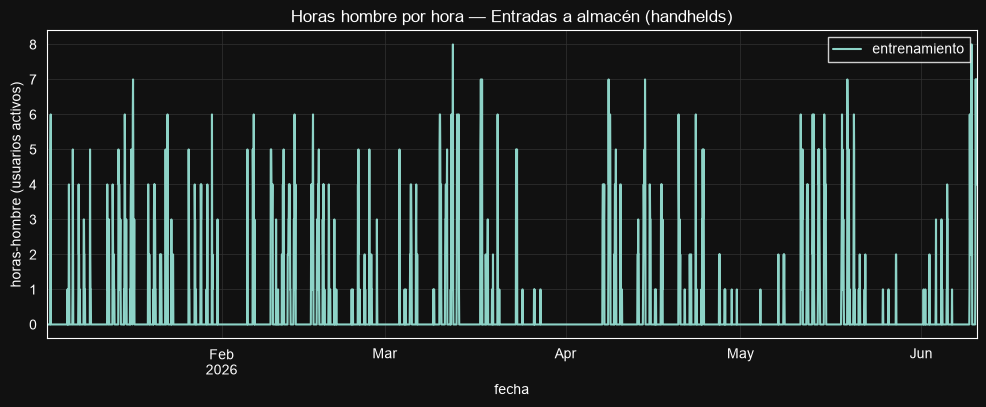

In [13]:
ax = train.plot(figsize=(12, 4), label="entrenamiento",
                title="Horas hombre por hora — Entradas a almacén (handhelds)")
ax.set_xlabel("fecha"); ax.set_ylabel("horas-hombre (usuarios activos)")
plt.legend(); plt.show()

**¿Es la serie estacionaria?** La media móvil de 24 h ayuda a ver la tendencia bajo el fuerte
ciclo diario.

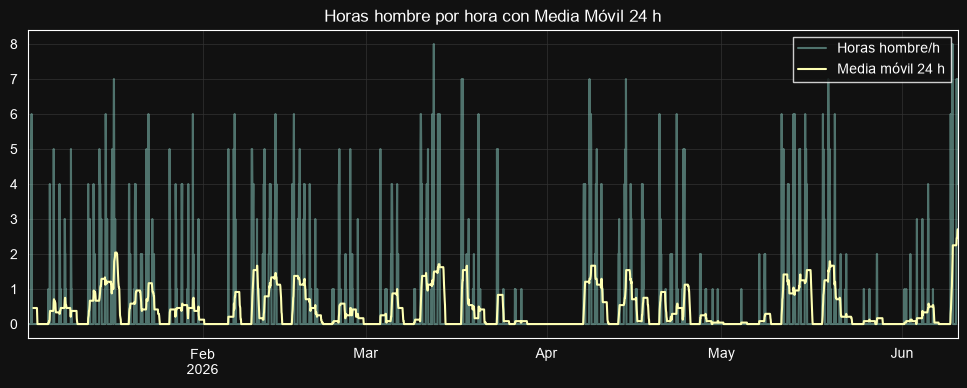

In [14]:
ax = train.plot(figsize=(12, 4), label="Horas hombre/h", alpha=0.5)
train.rolling(VENTANA_MM).mean().plot(ax=ax, label=f"Media móvil {VENTANA_MM} h")
plt.title(f"Horas hombre por hora con Media Móvil {VENTANA_MM} h")
plt.legend(); plt.show()

`seasonal_decompose` separa la serie en **tendencia**, **temporalidad** (perfil diario de 24 h)
y **residuos**. Usamos `period=24` (estacionalidad diaria) y modelo **aditivo** (los ceros nocturnos
hacen inapropiado el multiplicativo).

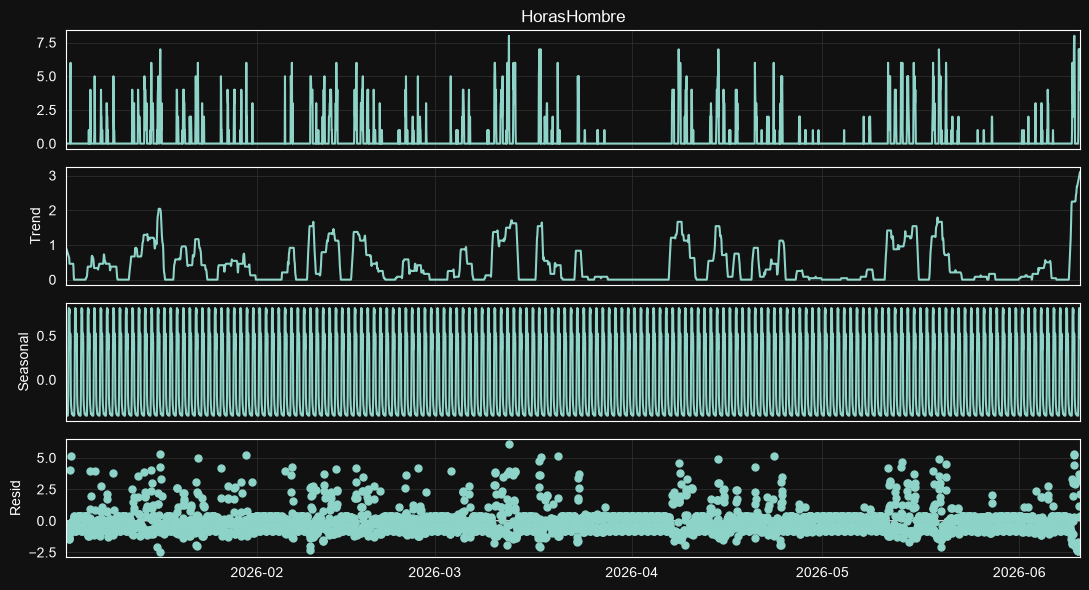

In [15]:
decomposition = seasonal_decompose(train, model="additive", period=PERIODO, extrapolate_trend="freq")
fig = decomposition.plot(); fig.set_size_inches(11, 6)
_oscurecer(fig); plt.show()

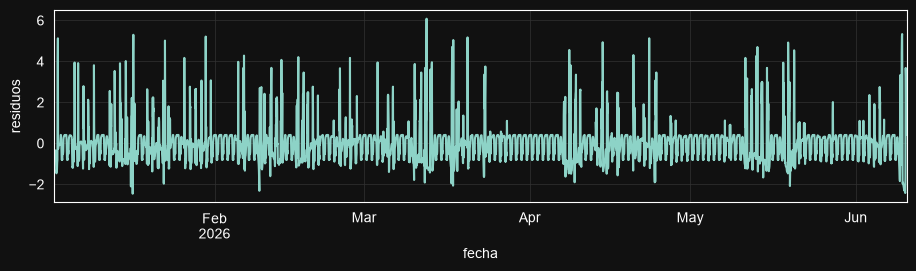

In [16]:
residuals = decomposition.resid
residuals.plot(figsize=(11, 2.5))
plt.ylabel("residuos"); plt.xlabel("fecha"); plt.show()

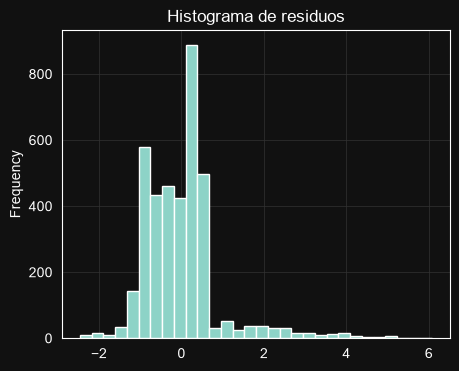

In [17]:
_ = residuals.dropna().plot.hist(figsize=(5, 4), bins=30)
plt.title("Histograma de residuos"); plt.show()

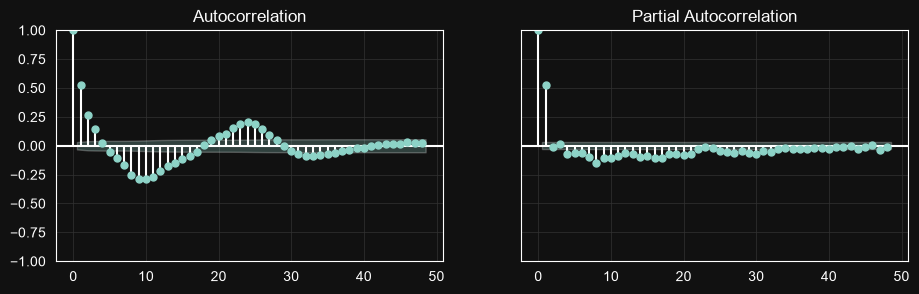

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
plot_acf(residuals.dropna(),  lags=LAGS, ax=axes[0])
plot_pacf(residuals.dropna(), lags=LAGS, ax=axes[1])
plt.show()

Las correlaciones significativas (sobre todo el **peine en 24 y 48 h**) indican que modelar la
serie con un **SARIMA estacional (s=24)** es buena idea. La estacionalidad **semanal (168 h)** se
añade como **exógenas de Fourier**: una sola ranura estacional no alcanza para 24 y 168 a la vez.

# Construcción del modelo SARIMA

## Estacionariedad de la serie (parámetro d)

**Test Dickey-Fuller** — H0: la serie *no* es estacionaria (si *p* es pequeña, se rechaza H0).

In [19]:
p_value_adfuller(train)

P-value:  4.506631566930963e-10
Se rechaza la hipótesis nula, los datos son estacionarios


La serie horaria ya es **estacionaria** (el ciclo diurno la hace revertir a la media), así que
**d = 0**. Mostramos igualmente la 1ª diferencia de forma ilustrativa.

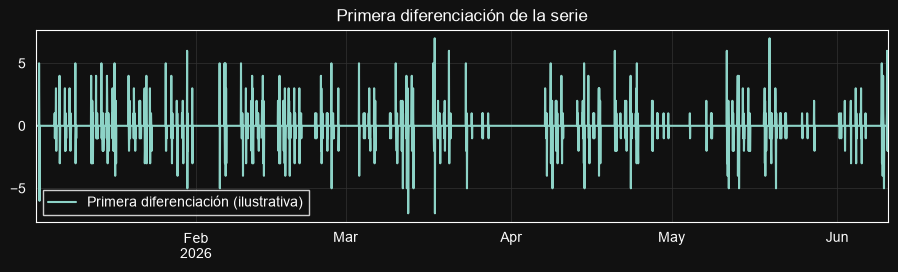

In [20]:
train_1diff = train - train.shift(1)
train_1diff.plot(figsize=(11, 2.5), label="Primera diferenciación (ilustrativa)")
plt.title("Primera diferenciación de la serie"); plt.legend(); plt.show()

In [21]:
p_value_adfuller(train_1diff.dropna())

P-value:  0.0
Se rechaza la hipótesis nula, los datos son estacionarios


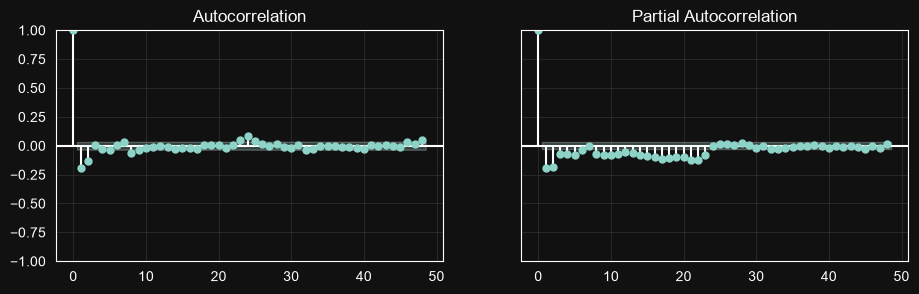

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
plot_acf(train_1diff.dropna(),  lags=LAGS, ax=axes[0])
plot_pacf(train_1diff.dropna(), lags=LAGS, ax=axes[1])
plt.show()

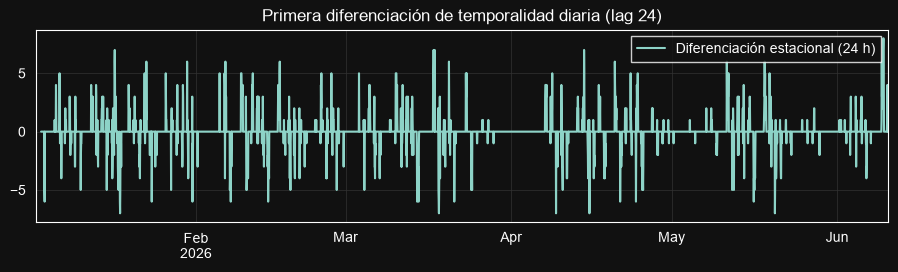

In [23]:
train_24diff = train - train.shift(PERIODO)
train_24diff.plot(figsize=(11, 2.5), label="Diferenciación estacional (24 h)")
plt.title("Primera diferenciación de temporalidad diaria (lag 24)"); plt.legend(); plt.show()

In [24]:
p_value_adfuller(train_24diff.dropna())

P-value:  1.4141043186324362e-21
Se rechaza la hipótesis nula, los datos son estacionarios


Por tanto **d = 0** y **D = 1** (una diferencia estacional en el lag 24). `D = 2` nunca.

## Estacionalidad semanal vía exógenas de Fourier (período 168)

SARIMA solo tiene **una** ranura estacional (la usamos para 24 h). El ciclo **semanal** (caída de fin
de semana) se inyecta como **términos de Fourier** (seno/coseno de período 168). La base es
determinista en el tiempo: se construye sobre un índice **continuo** que cubre train + futuro y luego
se **rebana** (no reiniciar `t` para el futuro, o la fase del fin de semana saldría mal).

In [25]:
def fourier_terms(index, period, K):
    """Matriz de términos de Fourier (seno/coseno) para una estacionalidad de longitud `period`."""
    t = np.arange(len(index))
    out = {}
    for k in range(1, K + 1):
        out[f"s{period}_sin{k}"] = np.sin(2 * np.pi * k * t / period)
        out[f"s{period}_cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(out, index=index)

exog = fourier_terms(datos.index, PERIODO_SEMANA, K_FOURIER)   # sobre TODA la serie (continua)
exog_train = exog.loc[:split_ts]
exog_fut   = exog.loc[split_ts + pd.Timedelta(hours=1):]
print(f"exóg. Fourier semanal: {exog.shape[1]} columnas | "
      f"train {exog_train.shape[0]} | futuro {exog_fut.shape[0]}")
exog.head()

exóg. Fourier semanal: 6 columnas | train 3830 | futuro 168


,s168_sin1,s168_cos1,s168_sin2,s168_cos2,s168_sin3,s168_cos3
2026-01-02 00:00:00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2026-01-02 01:00:00,0.037391,0.999301,0.074730,0.997204,0.111964,0.993712
2026-01-02 02:00:00,0.074730,0.997204,0.149042,0.988831,0.222521,0.974928
2026-01-02 03:00:00,0.111964,0.993712,0.222521,0.974928,0.330279,0.943883
2026-01-02 04:00:00,0.149042,0.988831,0.294755,0.955573,0.433884,0.900969


## Orden del modelo SARIMA (p, d, q) × (P, D, Q, 24)

Buscamos el orden con una rejilla **acotada** (p, q, P, Q ∈ {0, 1}; d = 0, D = 1, s = 24 ⇒ 16
ajustes), rankeada por AIC. Con ~4 000 puntos y s = 24 una rejilla mayor sería de minutos a horas;
mantenemos el espacio pequeño y cada ajuste protegido con `try/except`.

In [26]:
p = q = range(0, 2)
pdq = list(itertools.product(p, [0], q))                              # d = 0 fijo
P = Q = range(0, 2)
PDQs = [(x[0], 1, x[1], PERIODO) for x in itertools.product(P, Q)]    # D = 1, s = 24
print("No estacional (p,d,q):", pdq)
print("Estacional (P,D,Q,s) :", PDQs)

No estacional (p,d,q): [(0, 0, 0), (0, 0, 1), (1, 0, 0), (1, 0, 1)]
Estacional (P,D,Q,s) : [(0, 1, 0, 24), (0, 1, 1, 24), (1, 1, 0, 24), (1, 1, 1, 24)]


In [27]:
%%time
def fit_sarimax_model(parametros, parametros_s):
    try:
        modelo = SARIMAX(train, order=parametros, seasonal_order=parametros_s,
                         enforce_stationarity=False, enforce_invertibility=False)
        res = modelo.fit(disp=False, maxiter=50)
        return (parametros, parametros_s), res.aic
    except Exception:
        return (parametros, parametros_s), np.inf

resultados_grid = Parallel(n_jobs=4)(
    delayed(fit_sarimax_model)(o, s) for o in pdq for s in PDQs
)
aic_modelos = dict(resultados_grid)

/Users/AndresGonzalez/REPOS/Zeus-Notebooks/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


CPU times: user 202 ms, sys: 205 ms, total: 408 ms
Wall time: 1min 23s


In [28]:
mejor = min(aic_modelos, key=aic_modelos.get)
print("Mejor orden por AIC (rejilla sin exóg.):", mejor, "| AIC =", round(aic_modelos[mejor], 1))
aic_modelos

Mejor orden por AIC (rejilla sin exóg.): ((1, 0, 1), (1, 1, 1, 24)) | AIC = 9259.9


{((0, 0, 0), (0, 1, 0, 24)): np.float64(12758.385797167935),
 ((0, 0, 0), (0, 1, 1, 24)): np.float64(11420.93396176747),
 ((0, 0, 0), (1, 1, 0, 24)): np.float64(12223.4822936394),
 ((0, 0, 0), (1, 1, 1, 24)): np.float64(11171.836236067908),
 ((0, 0, 1), (0, 1, 0, 24)): np.float64(11740.964247458283),
 ((0, 0, 1), (0, 1, 1, 24)): np.float64(9979.315266744301),
 ((0, 0, 1), (1, 1, 0, 24)): np.float64(11008.959287320708),
 ((0, 0, 1), (1, 1, 1, 24)): np.float64(9873.127122167956),
 ((1, 0, 0), (0, 1, 0, 24)): np.float64(11424.185252860574),
 ((1, 0, 0), (0, 1, 1, 24)): np.float64(9325.95769498315),
 ((1, 0, 0), (1, 1, 0, 24)): np.float64(10521.287359762133),
 ((1, 0, 0), (1, 1, 1, 24)): np.float64(9311.708617518707),
 ((1, 0, 1), (0, 1, 0, 24)): np.float64(11398.86531819297),
 ((1, 0, 1), (0, 1, 1, 24)): np.float64(9300.38446450133),
 ((1, 0, 1), (1, 1, 0, 24)): np.float64(10494.165833914642),
 ((1, 0, 1), (1, 1, 1, 24)): np.float64(9259.859706530708)}

La rejilla orienta el orden, pero el **forecaster final** usa un orden **parsimonioso y
robusto** —`(1,0,1)(0,1,1,24)`, estilo *airline*— **con** las exógenas de Fourier semanal.
Hard-codear el orden rico del tutorial original `(1,1,2)(2,1,2,·)` sobre solo ~21 ciclos semanales
sería sobre-parametrizar.

In [29]:
modelo = SARIMAX(train, exog=exog_train,
                 order=(1, 0, 1), seasonal_order=(0, 1, 1, PERIODO),
                 enforce_stationarity=False, enforce_invertibility=False)
resultados = modelo.fit(disp=False, maxiter=50)
print(resultados.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
s168_sin1     -0.2954      0.085     -3.463      0.001      -0.463      -0.128
s168_cos1      0.0750      0.066      1.137      0.255      -0.054       0.204
s168_sin2      0.1358      0.078      1.752      0.080      -0.016       0.288
s168_cos2      0.1387      0.070      1.971      0.049       0.001       0.277
s168_sin3      0.0445      0.073      0.611      0.541      -0.098       0.187
s168_cos3      0.0043      0.067      0.064      0.949      -0.127       0.136
ar.L1          0.7046      0.011     63.038      0.000       0.683       0.727
ma.L1         -0.1215      0.014     -8.765      0.000      -0.149      -0.094
ma.S.L24      -1.0000      6.498     -0.154      0.878     -13.737      11.737
sigma2         0.6582      4.278      0.154      0.878      -7.727       9.044


# Validación

## Análisis de los residuos del modelo

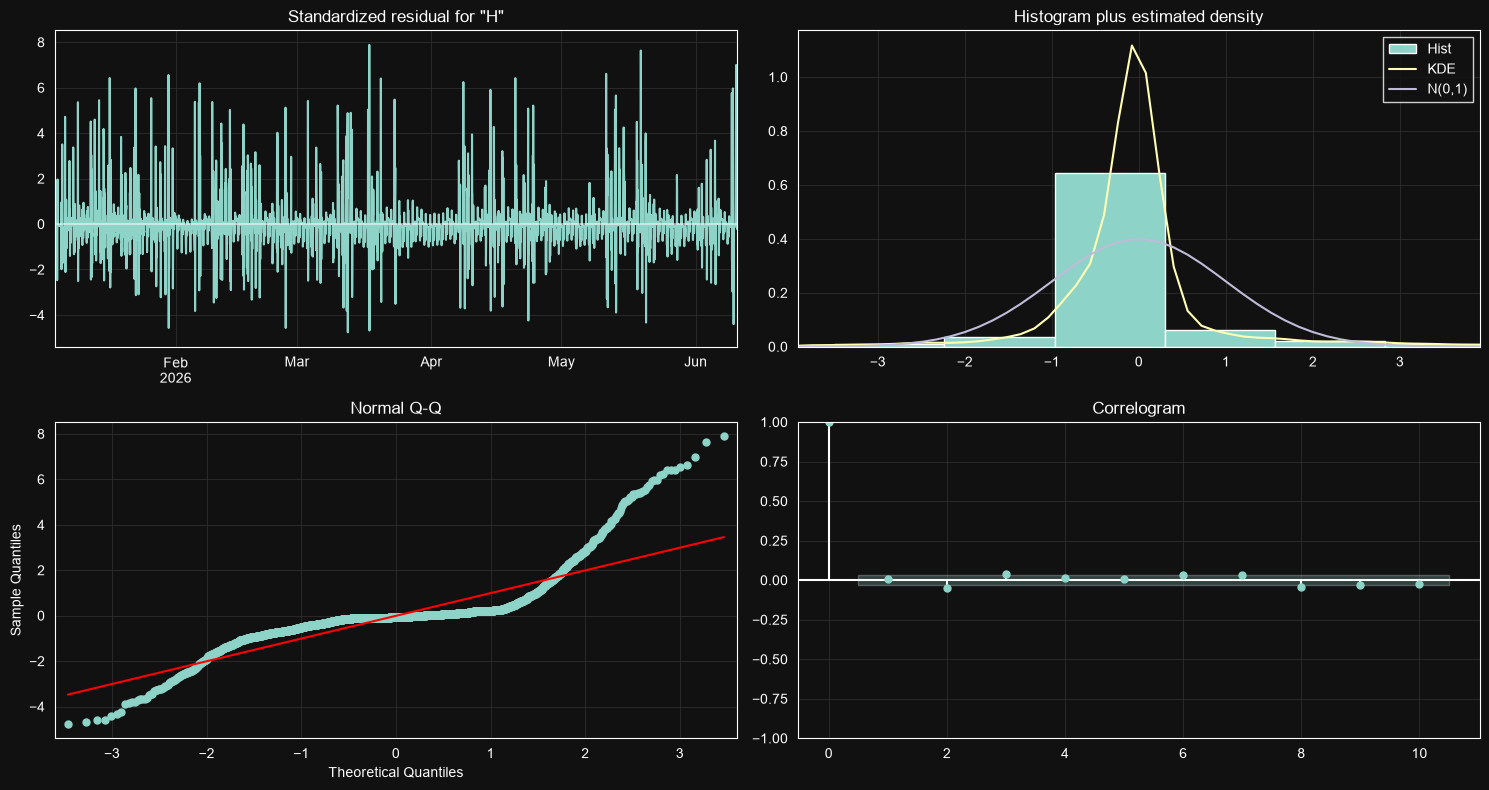

In [30]:
fig = resultados.plot_diagnostics(figsize=(15, 8))
_oscurecer(fig); plt.show()

## Predicción y evaluación del modelo (168 h)

In [31]:
pred = resultados.get_forecast(steps=len(test), exog=exog_fut)
pred_mean = pred.predicted_mean.clip(lower=0)   # las horas-hombre no pueden ser negativas
pred_mean.index = test.index                    # alinear al rango de prueba
pred_mean.head()

2026-06-10 14:00:00    3.000104
2026-06-10 15:00:00    2.547706
2026-06-10 16:00:00    1.991803
2026-06-10 17:00:00    1.076438
2026-06-10 18:00:00    0.744218
Freq: h, Name: predicted_mean, dtype: float64

In [32]:
pred_IC = pred.conf_int().clip(lower=0)
pred_IC.index = test.index
pred_IC.tail()

,lower HorasHombre,upper HorasHombre
2026-06-17 09:00:00,0.0,3.430028
2026-06-17 10:00:00,0.0,3.459394
2026-06-17 11:00:00,0.0,3.388832
2026-06-17 12:00:00,0.0,3.430908
2026-06-17 13:00:00,0.0,3.098189


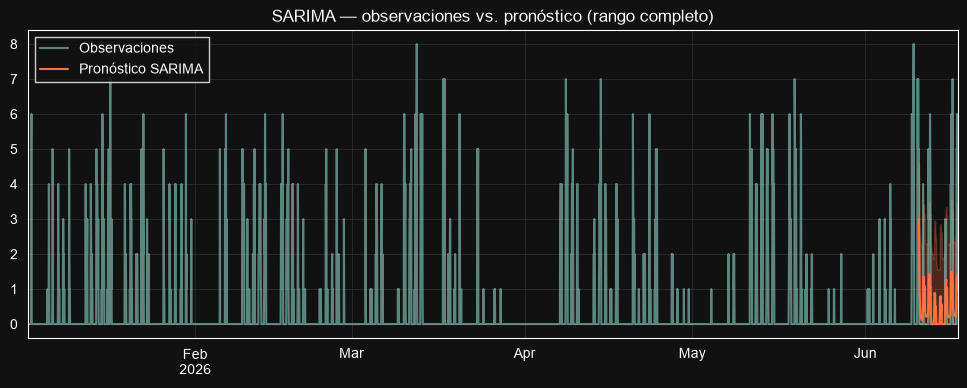

In [33]:
ax = datos["HorasHombre"].plot(label="Observaciones", figsize=(12, 4), alpha=0.6)
pred_mean.plot(ax=ax, label="Pronóstico SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.25)
plt.title("SARIMA — observaciones vs. pronóstico (rango completo)")
plt.legend(); plt.show()

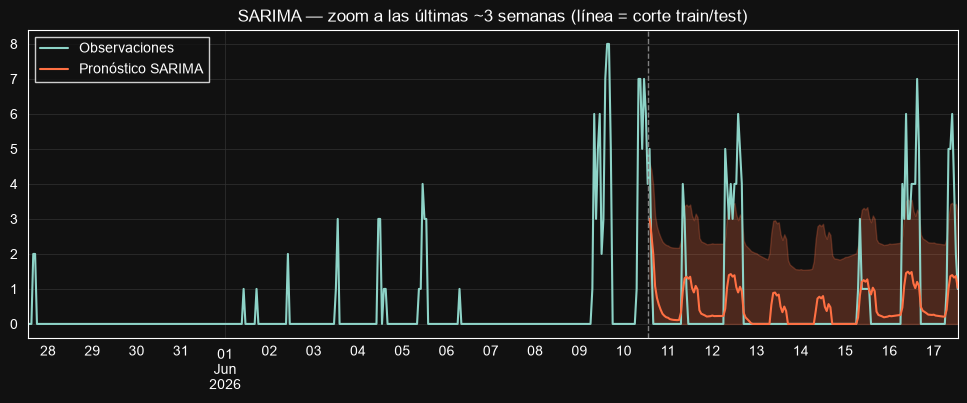

In [34]:
zoom = split_ts - pd.Timedelta(days=14)
ax = datos.loc[zoom:, "HorasHombre"].plot(label="Observaciones", figsize=(12, 4))
pred_mean.plot(ax=ax, label="Pronóstico SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.25)
plt.axvline(split_ts, color="gray", ls="--", lw=1)
plt.title("SARIMA — zoom a las últimas ~3 semanas (línea = corte train/test)")
plt.legend(); plt.show()

In [35]:
def metricas(y_real, y_pred, etiqueta):
    y_real, y_pred = y_real.align(y_pred, join="inner")
    assert y_pred.index.equals(y_real.index) and len(y_pred) == len(test)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae  = mean_absolute_error(y_real, y_pred)
    lab  = y_real.index.hour.isin(list(HORAS_LAB))
    rmse_lab = np.sqrt(mean_squared_error(y_real[lab], y_pred[lab]))
    pos  = y_real > 0
    mape = (np.abs((y_real[pos] - y_pred[pos]) / y_real[pos])).mean() * 100
    print(f"[{etiqueta}]  RMSE={rmse:.2f}  MAE={mae:.2f}  "
          f"RMSE(06-20h)={rmse_lab:.2f}  MAPE(y>0)={mape:.1f}%   [horas-hombre/h]")
    return rmse

rmse_sarima = metricas(test, pred_mean, "SARIMA")

[SARIMA]  RMSE=1.40  MAE=0.76  RMSE(06-20h)=1.77  MAPE(y>0)=58.8%   [horas-hombre/h]


# Prophet

Prophet ajusta un modelo **aditivo** con estacionalidades múltiples. Aquí brilla: maneja de forma
**nativa** la estacionalidad **diaria** (doble pico) y la **semanal** (caída de fin de semana), sin
exógenas. `yearly_seasonality=False` (solo ~25 semanas de datos).

In [36]:
train_Prophet = train.reset_index()
train_Prophet.columns = ["ds", "y"]
train_Prophet.tail()

,ds,y
3825,2026-06-10 09:00:00,7.0
3826,2026-06-10 10:00:00,5.0
3827,2026-06-10 11:00:00,7.0
3828,2026-06-10 12:00:00,6.0
3829,2026-06-10 13:00:00,4.0


## Modelo 1 — estacionalidad diaria + semanal

In [37]:
model_prophet = Prophet(daily_seasonality=True, weekly_seasonality=True,
                        yearly_seasonality=False, interval_width=0.95)
model_prophet.fit(train_Prophet)

16:21:53 [INFO] Chain [1] start processing


16:21:53 [INFO] Chain [1] done processing


In [38]:
future_data = model_prophet.make_future_dataframe(periods=PERIODOS_FUT, freq=FREQ)
pred_Prophet = model_prophet.predict(future_data)
pred_Prophet[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,yhat,yhat_lower,yhat_upper
3993,2026-06-17 09:00:00,1.332027,-0.624933,3.307494
3994,2026-06-17 10:00:00,1.482439,-0.704191,3.568367
3995,2026-06-17 11:00:00,1.404935,-0.486443,3.462956
3996,2026-06-17 12:00:00,1.229779,-0.860030,3.378424
3997,2026-06-17 13:00:00,1.098534,-1.053388,3.100891


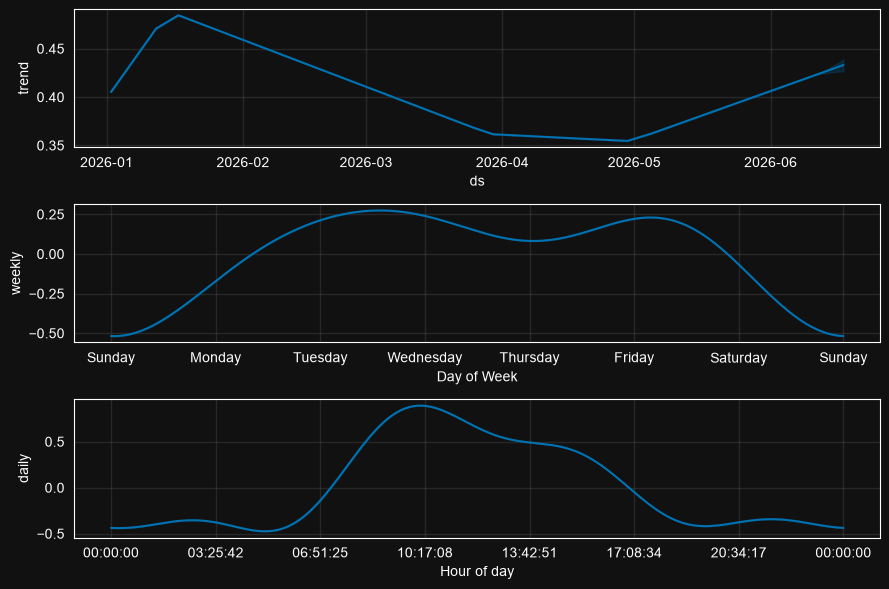

In [39]:
fig = model_prophet.plot_components(pred_Prophet, uncertainty=True, figsize=(9, 6))
_oscurecer(fig); plt.show()

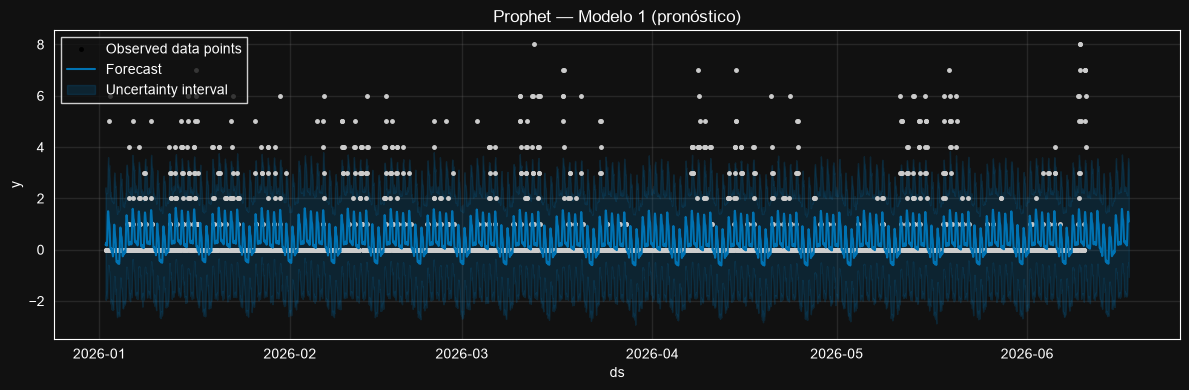

In [40]:
fig = model_prophet.plot(pred_Prophet, include_legend=True)
fig.set_size_inches(12, 4); plt.title("Prophet — Modelo 1 (pronóstico)")
_oscurecer(fig); plt.show()

In [41]:
prophet_pred = pred_Prophet.set_index("ds")["yhat"].clip(lower=0)
y_pred_p1 = prophet_pred.reindex(test.index)
rmse_prophet1 = metricas(test, y_pred_p1, "Prophet M1")

[Prophet M1]  RMSE=1.42  MAE=0.77  RMSE(06-20h)=1.78  MAPE(y>0)=60.2%   [horas-hombre/h]


## Modelo 2 — eventos de baja carga (festivos / cierres entre semana)

Donde el tutorial usaba "periodos de recesión", aquí modelamos los **días entre semana sin
actividad** (festivos MX / cierres) como *holidays* de Prophet. **No** incluimos fines de semana: ya
los captura `weekly_seasonality` (serían colineales).

In [42]:
# Días laborales (Lun–Vie) con CERO horas-hombre = festivos/cierres (data-driven).
carga_dia = datos["HorasHombre"].groupby(datos.index.normalize()).sum()
es_laboral = carga_dia.index.dayofweek < 5
cierres = carga_dia.index[(carga_dia.values == 0) & es_laboral]
eventos = pd.DataFrame({"holiday": "cierre_entre_semana", "ds": cierres})
eventos["lower_window"] = 0
eventos["upper_window"] = 0
print(f"Eventos de baja carga (festivos/cierres entre semana): {len(eventos)}")
eventos

Eventos de baja carga (festivos/cierres entre semana): 18


,holiday,ds,lower_window,upper_window
0,cierre_entre_semana,2026-02-02,0,0
1,cierre_entre_semana,2026-02-03,0,0
2,cierre_entre_semana,2026-02-04,0,0
3,cierre_entre_semana,2026-03-02,0,0
4,cierre_entre_semana,2026-03-16,0,0
5,cierre_entre_semana,2026-03-25,0,0
6,cierre_entre_semana,2026-03-30,0,0
7,cierre_entre_semana,2026-03-31,0,0
8,cierre_entre_semana,2026-04-01,0,0
9,cierre_entre_semana,2026-04-02,0,0


In [43]:
model_prophet2 = Prophet(daily_seasonality=True, weekly_seasonality=True,
                         yearly_seasonality=False, interval_width=0.95,
                         holidays=eventos if len(eventos) else None)  # robusto si no hay cierres
model_prophet2.fit(train_Prophet)

16:21:55 [INFO] Chain [1] start processing


16:21:55 [INFO] Chain [1] done processing


In [44]:
future_data2 = model_prophet2.make_future_dataframe(periods=PERIODOS_FUT, freq=FREQ)
pred_Prophet2 = model_prophet2.predict(future_data2)
pred_Prophet2.set_index("ds", inplace=True)

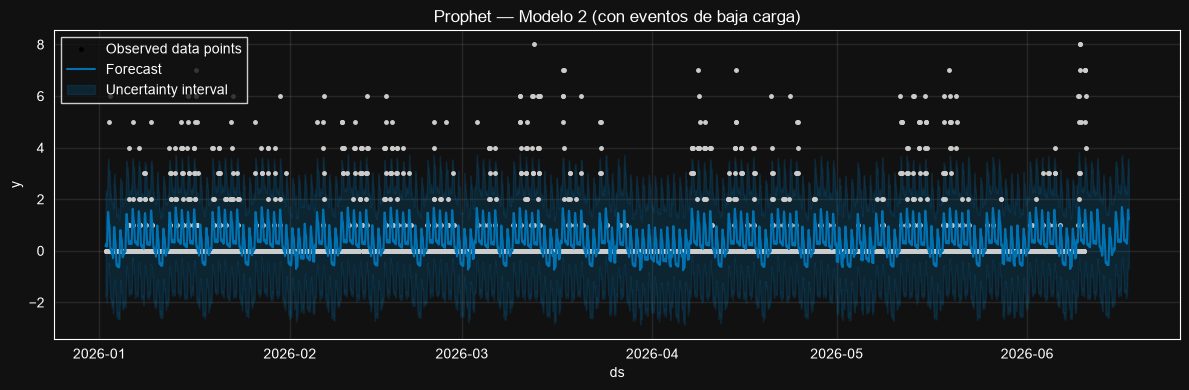

In [45]:
fig = model_prophet2.plot(pred_Prophet2.reset_index(), include_legend=True)
fig.set_size_inches(12, 4); plt.title("Prophet — Modelo 2 (con eventos de baja carga)")
_oscurecer(fig); plt.show()

In [46]:
int_conf_Prophet2 = pred_Prophet2[["yhat_lower", "yhat_upper"]].clip(lower=0)
int_conf_Prophet2.tail(PERIODOS_FUT).head()

,yhat_lower,yhat_upper
ds,,
2026-06-10 14:00:00,0.0,3.298731
2026-06-10 15:00:00,0.0,3.111511
2026-06-10 16:00:00,0.0,2.880791
2026-06-10 17:00:00,0.0,2.691325
2026-06-10 18:00:00,0.0,2.426187


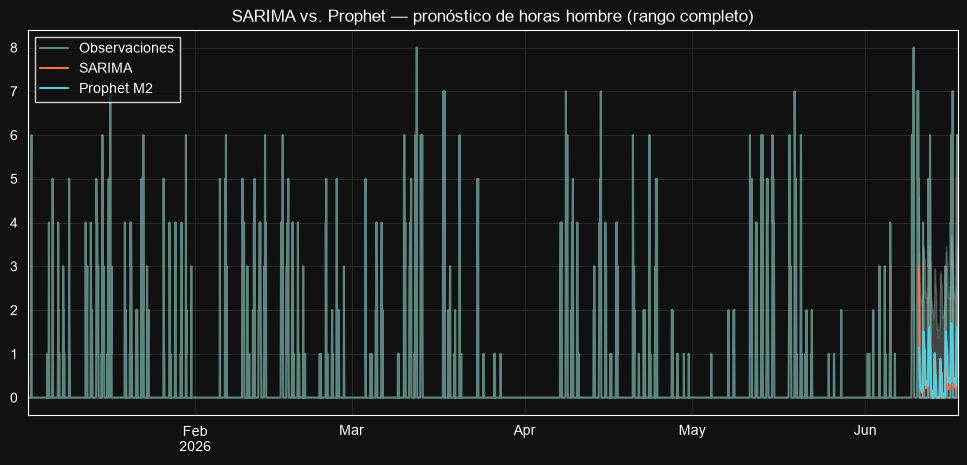

In [47]:
p2 = pred_Prophet2["yhat"].clip(lower=0).reindex(test.index)
ic2 = int_conf_Prophet2.reindex(test.index)

ax = datos["HorasHombre"].plot(label="Observaciones", figsize=(12, 5), alpha=0.6)
pred_mean.plot(ax=ax, label="SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.2)
p2.plot(ax=ax, label="Prophet M2", color="#4DD0E1")
ax.fill_between(test.index, ic2.iloc[:, 0], ic2.iloc[:, 1], color="#4DD0E1", alpha=0.2)
plt.title("SARIMA vs. Prophet — pronóstico de horas hombre (rango completo)")
plt.legend(); plt.show()

In [ ]:
# Comparación directa: solo las dos predicciones como LÍNEAS (sin la serie observada),
# cada una de un color, con su banda de varianza (IC 95%) y los outliers marcados.
# "Outlier" = observación real de la ventana de prueba que cae FUERA de AMBAS bandas
# de confianza (un pico/valle que ningún modelo anticipó).
fuera_sarima  = (test < pred_IC.iloc[:, 0]) | (test > pred_IC.iloc[:, 1])
fuera_prophet = (test < ic2.iloc[:, 0])     | (test > ic2.iloc[:, 1])
outliers = test[fuera_sarima & fuera_prophet]

ax = pred_mean.plot(figsize=(12, 5), label="Pronóstico SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1],
                color="#FF7043", alpha=0.20, label="Varianza SARIMA (IC 95%)")
p2.plot(ax=ax, label="Pronóstico Prophet M2", color="#4DD0E1")
ax.fill_between(test.index, ic2.iloc[:, 0], ic2.iloc[:, 1],
                color="#4DD0E1", alpha=0.20, label="Varianza Prophet (IC 95%)")
ax.plot(outliers.index, outliers.values, "o", color="#FF1744", markersize=7,
        label=f"Outliers fuera de banda ({len(outliers)})")
plt.title("SARIMA vs. Prophet — líneas de pronóstico, varianza y outliers")
plt.xlabel("fecha"); plt.ylabel("horas-hombre (usuarios activos)")
plt.legend(); plt.show()

In [ ]:
# Gráfica nativa de Prophet (como en el artículo): historia (puntos), línea de pronóstico
# y banda de incertidumbre sombreada. uncertainty=True dibuja el shade del IC 95%.
plot1 = model_prophet2.plot(pred_Prophet2.reset_index(), uncertainty=True)
plot1.set_size_inches(12, 5)
plt.title("Prophet M2 — pronóstico nativo con banda de incertidumbre")
_oscurecer(plot1); plt.show()

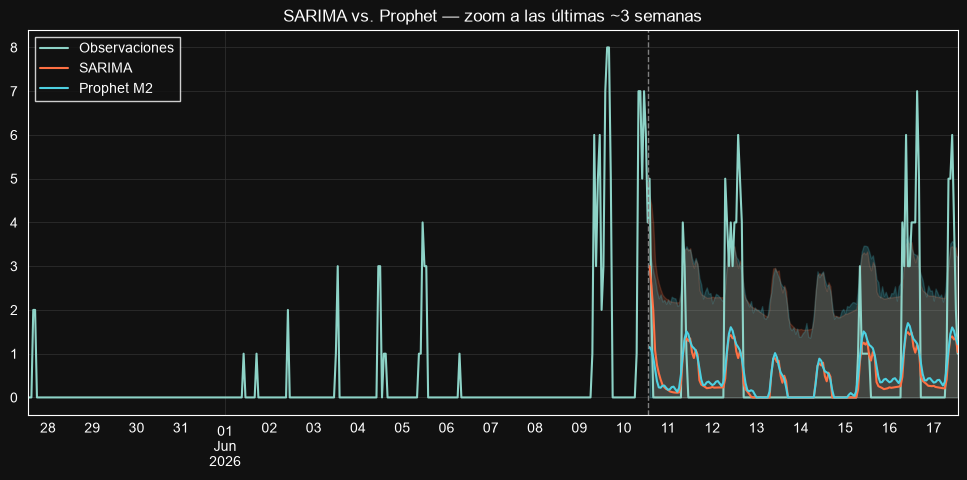

In [48]:
ax = datos.loc[zoom:, "HorasHombre"].plot(label="Observaciones", figsize=(12, 5))
pred_mean.plot(ax=ax, label="SARIMA", color="#FF7043")
ax.fill_between(pred_IC.index, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1], color="#FF7043", alpha=0.2)
p2.plot(ax=ax, label="Prophet M2", color="#4DD0E1")
ax.fill_between(test.index, ic2.iloc[:, 0], ic2.iloc[:, 1], color="#4DD0E1", alpha=0.2)
plt.axvline(split_ts, color="gray", ls="--", lw=1)
plt.title("SARIMA vs. Prophet — zoom a las últimas ~3 semanas")
plt.legend(); plt.show()

In [49]:
rmse_prophet2 = metricas(test, p2, "Prophet M2")
print()
print(f"RMSE  SARIMA={rmse_sarima:.2f} | Prophet M1={rmse_prophet1:.2f} | "
      f"Prophet M2={rmse_prophet2:.2f}   [horas-hombre/h]")

[Prophet M2]  RMSE=1.39  MAE=0.81  RMSE(06-20h)=1.75  MAPE(y>0)=60.0%   [horas-hombre/h]

RMSE  SARIMA=1.40 | Prophet M1=1.42 | Prophet M2=1.39   [horas-hombre/h]


## Conclusión y advertencias

- Se compara el **error puntual** (RMSE/MAE), no el ancho de banda: SARIMA usa IC analítico de
  espacio de estados y Prophet, muestreo — no son equivalentes.
- El **horizonte es de 168 h**: solo las primeras ~24–72 h tienen banda estrecha; los días 4–7 son
  indicativos. La banda inferior se recortó a 0 (conservadora).
- **Caveats:** la variable es un **proxy de presencia** (no horas de nómina); el *snapshot* es de
  ~6 meses (ene–jun 2026), por lo que solo son creíbles horizontes de **días a semanas** y no
  hay efecto anual estimable. La estacionalidad **semanal** la captura Prophet de forma nativa y
  SARIMA vía **exógenas de Fourier**.
- Para producción conviene **volver a consultar el API SGA** y reentrenar; el orden SARIMA y
  `K_FOURIER` son ajustables según evolucione la operación.

# Apéndice — serie de horario laboral 06–20h (s=15) · solo comparación

⚠️ **Caveat de pseudo-continuidad:** al quitar las horas 21–05h, el *lag* estacional s=15 salta
huecos reales (noche y fin de semana), así que las distancias del modelo dejan de coincidir con el
tiempo de reloj. **No** es el pronóstico reportado; se incluye solo como comparación rápida.

In [50]:
ent_lab = ent[ent["hora"].between(6, 20)]
hh_lab = ent_lab.groupby("ts")["usuario"].nunique()
rejilla_lab = pd.DatetimeIndex([
    d + pd.Timedelta(hours=h)
    for d in pd.date_range(hh_lab.index.min().floor("D"), hh_lab.index.max().floor("D"), freq="D")
    for h in HORAS_LAB
])
serie_lab = hh_lab.reindex(rejilla_lab).fillna(0).astype(float)
print(f"Serie laboral 06-20h: {len(serie_lab):,} puntos (s=15), {(serie_lab == 0).mean():.0%} ceros")

Serie laboral 06-20h: 2,505 puntos (s=15), 77% ceros


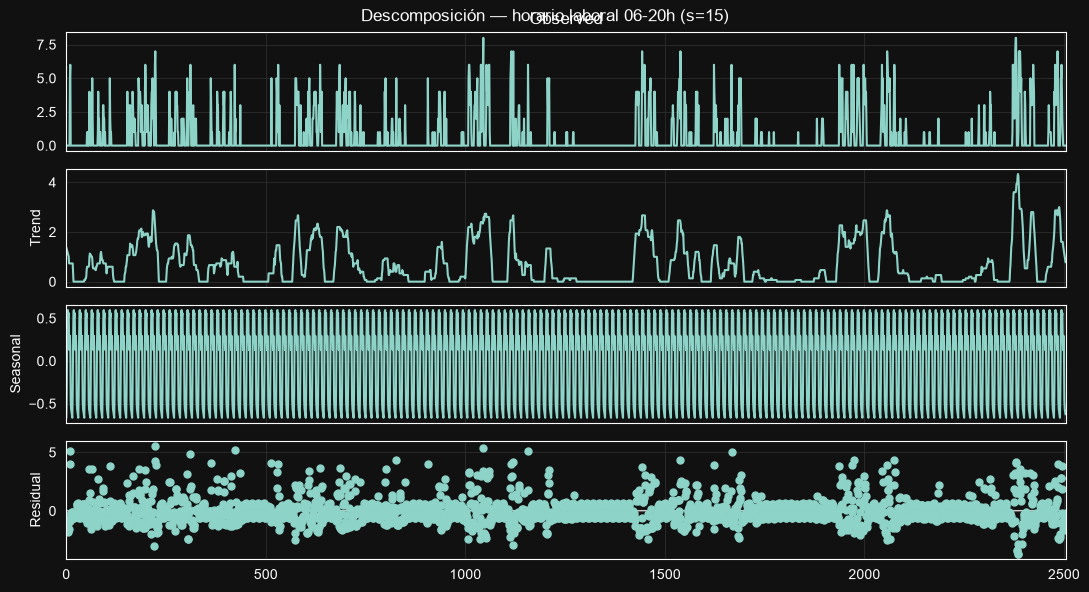

In [51]:
dec_lab = seasonal_decompose(serie_lab.to_numpy(), model="additive", period=15, extrapolate_trend="freq")
fig = dec_lab.plot(); fig.set_size_inches(11, 6)
_oscurecer(fig); plt.suptitle("Descomposición — horario laboral 06-20h (s=15)"); plt.show()

# Acertividad del modelo y diagnóstico de la incertidumbre

Las celdas siguientes evalúan **qué tan acertado** es el pronóstico frente a las observaciones de la
semana de prueba (168 h) y **por qué la banda de incertidumbre es ancha**. El RMSE puntual de arriba
(~1.4 para los tres modelos) no cuenta toda la historia: con **86 % de ceros** la métrica global está
dominada por noches y fines de semana que cualquier método acierta. Medimos en tres ejes:

1. **Error contra líneas base** — ¿el modelo le gana a una *persistencia estacional* (misma hora de la
   semana / del día anterior)? Si no, no está aportando señal sobre algo trivial.
2. **Calibración de la incertidumbre** — cobertura empírica del intervalo nominal al 95 % y su
   **anchura** (nitidez). Ancho *y* sobre-cubierto ⇒ banda pesimista; ancho *y* sub-cubierto ⇒ mal
   calibrado.
3. **Sesgo y perfil del error** — ¿dónde falla? (picos vs. valles, por hora del día, por horizonte).

De ese diagnóstico salen las **recomendaciones de manejo de datos** al final del notebook.

> Nota: estas celdas **solo leen** objetos ya calculados arriba (`test`, `pred_mean`, `pred_IC`,
> `y_pred_p1`, `p2`, `ic2`); ejecútalas después de haber corrido SARIMA y Prophet.

In [ ]:
# === Acertividad · 1) Líneas base de persistencia estacional ===
# Referencia mínima: si el modelo no le gana a «repetir la semana/el día anterior», no aporta señal.
# naïve-168 = misma hora de la semana pasada | naïve-24 = misma hora de ayer.
serie_full = datos["HorasHombre"]
naive_168 = serie_full.shift(PERIODO_SEMANA).reindex(test.index)
naive_24  = serie_full.shift(PERIODO).reindex(test.index)

def resumen_metricas(y_real, y_pred):
    """Métricas de acertividad sobre la ventana de prueba (alineadas por índice)."""
    y_real, y_pred = y_real.align(y_pred, join="inner")
    err = y_pred - y_real
    lab = y_real.index.hour.isin(list(HORAS_LAB))     # solo horario operativo 06–20h
    pos = y_real > 0
    return {
        "RMSE":       np.sqrt(np.mean(err ** 2)),
        "RMSE_06_20": np.sqrt(np.mean(err[lab] ** 2)),  # donde de verdad hay carga
        "MAE":        np.mean(np.abs(err)),
        "MAPE%_y>0":  (np.abs(err[pos] / y_real[pos])).mean() * 100,
        "Sesgo(ME)":  err.mean(),                       # + sobrestima · − subestima
    }

preds = {
    "SARIMA":     pred_mean,
    "Prophet M1": y_pred_p1,
    "Prophet M2": p2,
    "naïve-168":  naive_168,
    "naïve-24":   naive_24,
}
print(f"Líneas base listas | NaN naïve-168={int(naive_168.isna().sum())} naïve-24={int(naive_24.isna().sum())}")

In [ ]:
# === Acertividad · 2) Tabla comparativa + «skill score» vs. persistencia (naïve-168) ===
tabla = pd.DataFrame({k: resumen_metricas(test, v) for k, v in preds.items()}).T
rmse_ref = tabla.loc["naïve-168", "RMSE_06_20"]
tabla["Skill_vs_naïve168"] = 1 - tabla["RMSE_06_20"] / rmse_ref   # >0 supera a la base · <0 peor
tabla = tabla.sort_values("RMSE_06_20")
print("Menor RMSE(06-20h) = mejor. Skill>0 ⇒ supera a «repetir la semana anterior».\n")
display(tabla.round(2))

In [ ]:
# === Acertividad · 3) Calibración de la incertidumbre (el problema de la banda ancha) ===
# Cobertura empírica (nominal 95%) y nitidez (anchura). Ancho/μ compara la banda con el nivel típico
# de carga: >1 ⇒ la banda es más ancha que la propia señal (poco útil para planear personal).
def cobertura(y_real, low, high):
    y_real, low = y_real.align(low, join="inner")
    _, high     = y_real.align(high, join="inner")
    dentro = (y_real >= low) & (y_real <= high)
    lab = y_real.index.hour.isin(list(HORAS_LAB))
    ancho = high - low
    mu_lab = max(test[test.index.hour.isin(list(HORAS_LAB))].mean(), 1e-9)
    return {
        "Cobertura_global%": dentro.mean() * 100,
        "Cobertura_06_20%":  dentro[lab].mean() * 100,
        "Ancho_medio":       ancho.mean(),
        "Ancho_06_20":       ancho[lab].mean(),
        "Ancho/μ_obs":       ancho[lab].mean() / mu_lab,
    }

ic_eval = pd.DataFrame({
    "SARIMA (IC analítico)": cobertura(test, pred_IC.iloc[:, 0], pred_IC.iloc[:, 1]),
    "Prophet M2 (muestreo)": cobertura(test, ic2.iloc[:, 0], ic2.iloc[:, 1]),
}).T
print("Nominal = 95%. Cobertura ≫ 95% con ancho grande ⇒ banda pesimista (sobre-ancha).\n")
display(ic_eval.round(2))

In [ ]:
# === Acertividad · 4) ¿Por qué es «conservador»? Regresión a la media ===
# Un modelo conservador aplana: subestima los picos y sobrestima los valles -> banda ancha al centro.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

lab_idx = test.index[test.index.hour.isin(list(HORAS_LAB))]   # solo horario operativo 06-20h
obs_lab = test.reindex(lab_idx)

# (a) Predicho vs. real: la diagonal es la predicción perfecta; aplanarse hacia la media = conservador
ax = axes[0]
for nombre, yp, color in [("SARIMA", pred_mean, "#FF7043"), ("Prophet M2", p2, "#4DD0E1")]:
    ax.scatter(obs_lab, yp.reindex(lab_idx), s=18, alpha=0.5, label=nombre, color=color)
lim = float(obs_lab.max())
ax.plot([0, lim], [0, lim], "w--", lw=1, label="ideal")
ax.set_xlabel("Observado (h-hombre/h)"); ax.set_ylabel("Pronosticado")
ax.set_title("Predicho vs. real (06–20h)"); ax.legend()

# (b) Razón pronóstico/observado en picos (decil superior) y valles (decil inferior, y>0)
q_alto = obs_lab.quantile(0.8)
q_bajo = obs_lab[obs_lab > 0].quantile(0.2)
filas = []
for nombre, yp in [("SARIMA", pred_mean), ("Prophet M1", y_pred_p1), ("Prophet M2", p2)]:
    yl = yp.reindex(lab_idx)
    pico  = yl[obs_lab >= q_alto].mean() / obs_lab[obs_lab >= q_alto].mean()
    valle = (yl[(obs_lab > 0) & (obs_lab <= q_bajo)].mean()
             / obs_lab[(obs_lab > 0) & (obs_lab <= q_bajo)].mean())
    filas.append((nombre, pico, valle))
captura = pd.DataFrame(filas, columns=["modelo", "captura_pico", "captura_valle"]).set_index("modelo")
captura.plot.bar(ax=axes[1]); axes[1].axhline(1, color="gray", ls="--")
axes[1].set_title("Razón pronóstico/observado (1 = perfecto)"); axes[1].set_ylabel("razón")
plt.tight_layout(); plt.show()
print("captura_pico < 1 ⇒ subestima picos (conservador) · captura_valle > 1 ⇒ sobrestima valles.")
display(captura.round(2))

In [ ]:
# === Acertividad · 5) ¿Dónde y cuándo falla? Error por hora del día y por horizonte ===
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# (a) MAE por hora del día — la acción está en el horario operativo (sombreado)
ax = axes[0]
for nombre, yp, color in [("SARIMA", pred_mean, "#FF7043"), ("Prophet M2", p2, "#4DD0E1")]:
    ae = (yp - test).abs()
    ae.groupby(ae.index.hour).mean().plot(ax=ax, marker="o", label=nombre, color=color)
ax.axvspan(min(HORAS_LAB), max(HORAS_LAB), color="gray", alpha=0.15)
ax.set_xlabel("hora del día"); ax.set_ylabel("MAE (h-hombre/h)")
ax.set_title("Error medio por hora del día"); ax.legend()

# (b) RMSE por día de horizonte (lead time): el pronóstico se degrada con la distancia
ax = axes[1]
dia_horizonte = ((test.index - test.index.min()) / pd.Timedelta(hours=24)).astype(int) + 1
for nombre, yp, color in [("SARIMA", pred_mean, "#FF7043"), ("Prophet M2", p2, "#4DD0E1")]:
    err = yp - test
    err.groupby(dia_horizonte).apply(lambda e: np.sqrt(np.mean(e ** 2))).plot(
        ax=ax, marker="o", label=nombre, color=color)
ax.set_xlabel("día de horizonte (1 = primer día)"); ax.set_ylabel("RMSE")
ax.set_title("Degradación por horizonte"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# === Acertividad · 6) Cuantificación de outliers y del régimen de ceros ===
# Motiva el manejo de datos: cola derecha pesada + muchos ceros = varianza inflada y media aplanada.
y = datos["HorasHombre"]
pos = y[y > 0]
q1, q3 = pos.quantile([0.25, 0.75]); iqr = q3 - q1
valla_sup = q3 + 1.5 * iqr
out_altos = pos[pos > valla_sup]

print(f"Horas totales en la serie          : {len(y):,}")
print(f"  · % de ceros (cerrado/noche)     : {(y == 0).mean():.1%}")
print(f"  · % de horas con carga (>0)      : {(y > 0).mean():.1%}")
print("Distribución de las horas con carga (>0):")
print(f"  · mediana / media                : {pos.median():.1f} / {pos.mean():.2f}")
print(f"  · asimetría / curtosis           : {pos.skew():.2f} / {pos.kurt():.2f}   (>0 ⇒ cola derecha pesada)")
print(f"  · valla IQR superior (Q3+1.5·IQR) : {valla_sup:.1f}")
print(f"  · outliers por encima            : {len(out_altos):,} ({len(out_altos)/len(pos):.1%} de las horas con carga)")
print(f"  · máximo / mediana               : {pos.max():.0f} / {pos.median():.0f}  (factor ×{pos.max()/max(pos.median(), 1):.1f})")

# Dispersión por hora del día: heterocedasticidad y picos concentrados en el horario operativo.
ax = (datos.assign(hora=datos.index.hour)
      .boxplot(column="HorasHombre", by="hora", figsize=(12, 4), grid=False))
plt.suptitle(""); plt.title("Dispersión de horas-hombre por hora del día (puntos = outliers)")
plt.xlabel("hora del día"); plt.ylabel("h-hombre/h"); plt.show()

## Recomendaciones para el manejo de la data (subir acertividad y estrechar la banda)

El diagnóstico muestra un patrón claro: los tres modelos **empatan** en ~1.4 RMSE y ~59 % MAPE, el
intervalo al 95 % **sobre-cubre** con un ancho mayor que la propia señal, y el pronóstico **aplana**
(subestima picos, sobrestima valles). Las causas son de **datos**, no de hiperparámetros. En orden de
impacto esperado:

### 1. Separar el régimen «abierto/cerrado» del régimen de intensidad — *la de mayor impacto*
El **86 % de ceros** (noche, fin de semana, cierres) mete a SARIMA/Prophet en una serie **bimodal**:
para reconciliar «0» con «pico» inflan la varianza (banda ancha) y tiran la media al centro
(conservador). **Modelar dos cosas por separado:**
  - un **clasificador de calendario** «¿hay operación en esta hora?» (laboral × horario × festivo);
  - un **modelo de intensidad** de horas-hombre **condicionado a que haya operación** (entrena solo
    sobre las horas con carga, no sobre los ceros estructurales).

  El pronóstico final = `P(abierto) × intensidad`. Esto por sí solo estrecha la banda drásticamente
  porque la varianza deja de mezclar los dos mundos. El apéndice 06–20h es un primer paso en esta línea.

### 2. Modelar en escala transformada / como conteo — *arregla la banda «conservadora»*
La variable es un **conteo de usuarios** (enteros pequeños, máx ~7). El IC gaussiano de SARIMA es
**simétrico** y cruza a negativo (en Prophet `yhat_lower` llega a −1.0 antes de recortar a 0): por eso
la banda inferior pegada a 0 se ve pesimista, y `ma.S.L24` topa en −1 con `sigma2` mal identificada.
  - Ajustar sobre **`log1p(y)`** o **raíz / Anscombe** (estabiliza varianza y doma la cola) y deshacer
    la transformación al final → bandas **no negativas y asimétricas**, más nítidas.
  - O usar un modelo **de conteo** (Poisson / Binomial-Negativa: `statsmodels` GLM, o
    `GradientBoosting`/`skforecast` con pérdida Poisson). Para un conteo de presencia es lo correcto.

### 3. Tratar los outliers explícitamente, no dejarlos inflar σ
La cola derecha (skew/curtosis altos en la celda de outliers) eleva la `sigma2` estimada y ensancha
**toda** la banda:
  - **Winsorizar / cap** los picos extremos antes de ajustar (p. ej. al percentil 99); o
  - marcar los picos conocidos como **regresores de intervención** (inventarios, promociones,
    recepciones masivas) en `exog` (SARIMAX) o `add_regressor` (Prophet), para que el modelo los
    *explique* en vez de *promediarlos*.

### 4. Enriquecer con regresores exógenos de calendario/operación
Hoy SARIMA solo recibe Fourier semanal y Prophet un puñado de «cierres» deducidos de ceros. Añadir:
  - **calendario de festivos MX** y de **cierres/inventarios** reales (no solo los inferidos);
  - **día de quincena / fin de mes**, turnos, y **citas de recepción** programadas (el SGA las tiene:
    `citas`, OC pendientes) como *leading indicators* del volumen.

  Un regresor que anticipe el pico sube la captura de picos y estrecha la banda donde más importa.

### 5. Validar con *backtesting* de origen móvil (no un solo corte)
El RMSE de arriba sale de **una** semana de holdout: estimación frágil. Repetir el pronóstico sobre
**varios orígenes deslizantes** (6–8 cortes semanales) y reportar la **distribución** del error y de la
**cobertura**. Es la única forma de afirmar la acertividad con confianza, y permite calibrar intervalos
**empíricos / conformes** (cuantiles de los residuos del backtest), honestos y más estrechos que el IC
gaussiano.

### 6. Reportar y optimizar por horizonte de negocio
La celda «degradación por horizonte» muestra que solo los primeros días son fiables. Si la decisión de
staffing es a **24–48 h**, evaluar y elegir el modelo **para ese horizonte corto**, no para 168 h.

### 7. Revisar la definición y el grano de la variable objetivo
- Con solo **576 horas activas** en ~5.5 meses y un conteo de 1–7 usuarios, la señal por hora es
  **lumpy** y el MAPE explota. Probar las alternativas ya esbozadas (tiempo laborado `dur_min/60`, o
  volumen de tareas).
- Considerar un **grano más grueso** (horas-hombre por **turno** o por **día**), donde la relación
  señal/ruido es mucho mejor, y luego **desagregar** con el perfil diario.

> **Quick wins** (orden sugerido): (2) `log1p` + (1) entrenar solo en horas operativas → banda más
> estrecha y realista de inmediato; luego (5) backtesting móvil para medir bien y (4) regresores de
> citas/festivos para ganar acertividad estructural.